<a href="https://colab.research.google.com/github/sitiekbal/CapstnPro_Econ.Analysis/blob/main/Capstone_Project_Economic_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 36 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Country                                         144 non-null    object 
 1   Year                                            144 non-null    int64  
 2   GDP (in Trillions USD)                          144 non-null    float64
 3   GDP per Capita (in USD)                         144 non-null    float64
 4   Inflation Rate (%)                              144 non-null    float64
 5   Population (in Millions)                        144 non-null    float64
 6   Population Growth Rate (%)                      144 non-null    float64
 7   Urban Population (%)                            144 non-null    float64
 8   Life Expectancy (Years)                         144 non-null    float64
 9   Healthcare Expenditure

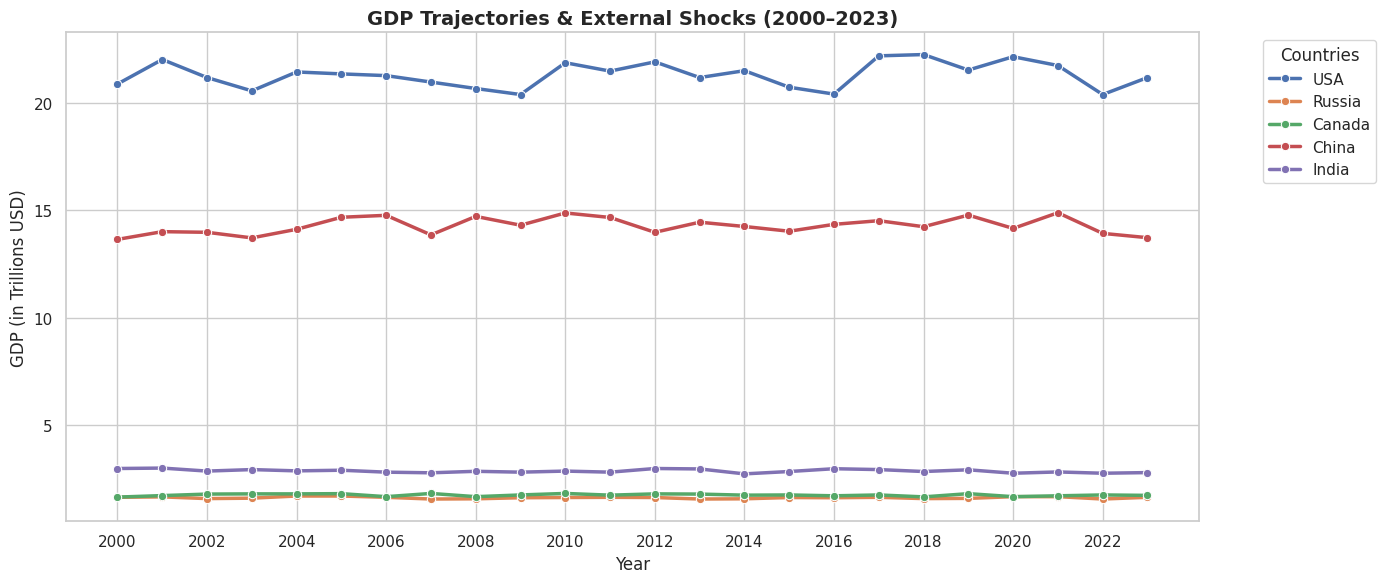

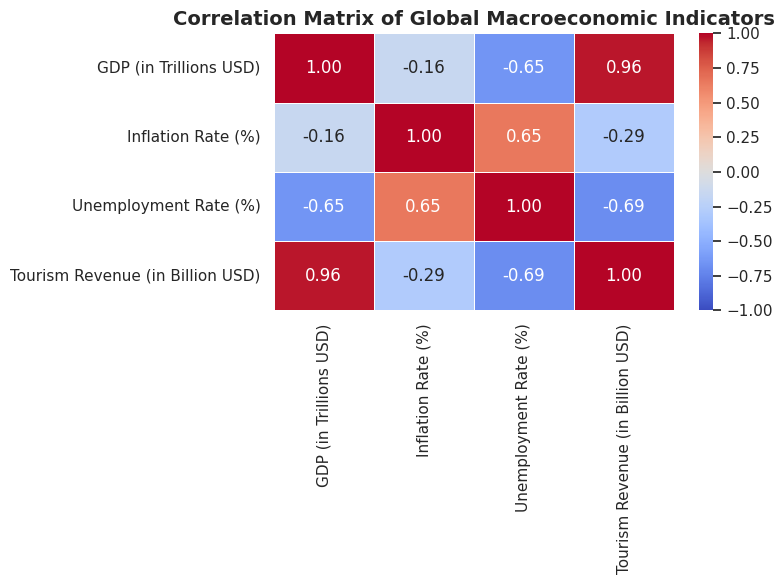

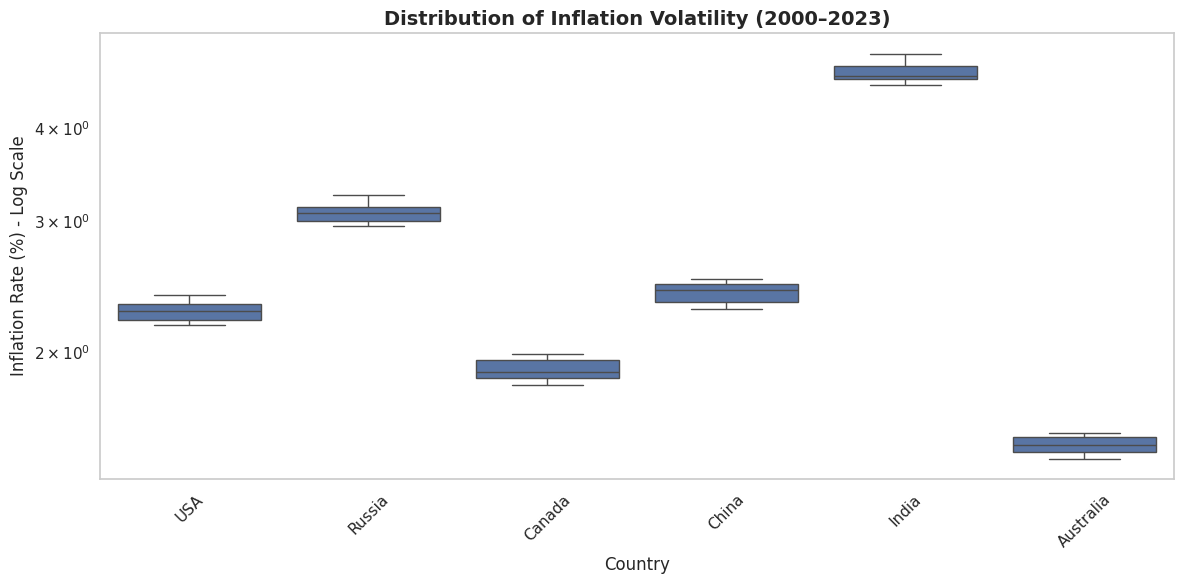

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for professional academic plotting
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# ==========================================
# 1. DATA LOADING & CLEANING
# ==========================================

# Load dataset using its correct location
df = pd.read_csv('/content/Global Economic Data.csv')

# Filter for the capstone scope: 2000 to 2023
df = df[(df['Year'] >= 2000) & (df['Year'] <= 2023)]

# Display structural overview
print("--- Dataset Info ---")
print(df.info())
print("\n--- Missing Values Per Column ---")
print(df.isnull().sum())


# ==========================================
# 2. VISUALIZATION MAPS
# ==========================================

# --- Map A: Time-Series Line Plot (GDP Trajectories) ---
target_countries = df['Country'].unique()[:5]
df_filtered = df[df['Country'].isin(target_countries)]

plt.figure(figsize=(14, 6))
sns.lineplot(data=df_filtered, x='Year', y='GDP (in Trillions USD)', hue='Country', marker='o', linewidth=2.5)
plt.title('GDP Trajectories & External Shocks (2000–2023)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('GDP (in Trillions USD)', fontsize=12)
plt.xticks(range(2000, 2024, 2))
plt.legend(title='Countries', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


# --- Map B: Correlation Heatmap (Macroeconomic Links) ---
plt.figure(figsize=(8, 6))
# Focus columns updated to match the exact names in the CSV
macro_cols = ['GDP (in Trillions USD)', 'Inflation Rate (%)', 'Unemployment Rate (%)', 'Tourism Revenue (in Billion USD)']
corr_matrix = df[macro_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix of Global Macroeconomic Indicators', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


# --- Map C: Distribution Box Plot (Regional Volatility) ---
# Note: Since 'Region' column is not in your df.info() list, we use 'Country' or another category.
# If your CSV does not have a 'Region' column, we will plot by 'Country'.
if 'Region' in df.columns:
    x_col = 'Region'
else:
    x_col = 'Country'

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x=x_col, y='Inflation Rate (%)')
plt.yscale('log') # Useful if you have hyperinflation outliers skewing the scale
plt.title('Distribution of Inflation Volatility (2000–2023)', fontsize=14, fontweight='bold')
plt.xlabel(x_col, fontsize=12)
plt.ylabel('Inflation Rate (%) - Log Scale', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Visualizing Objective 1: GDP & Shock Velocity (2000–2023)

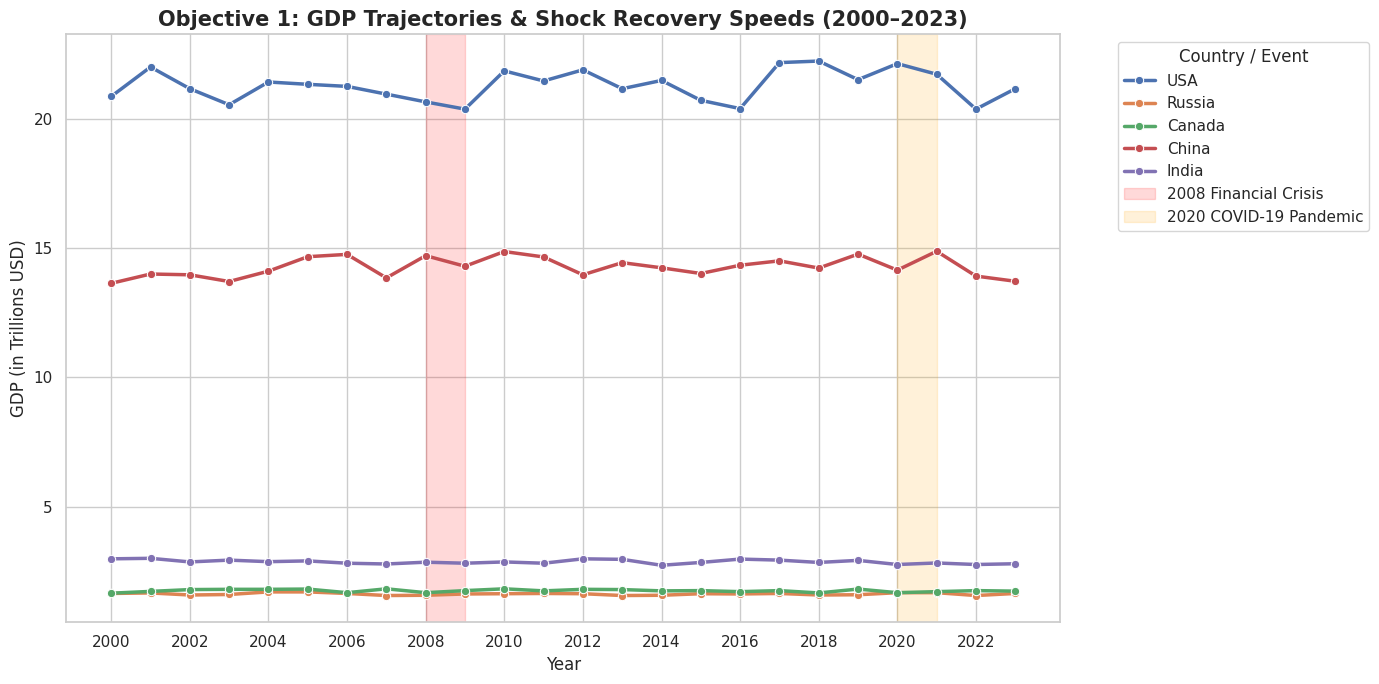

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

# Line plot representing GDP trajectory for target countries
target_countries = df['Country'].unique()[:5]
df_obj1 = df[df['Country'].isin(target_countries)]

sns.lineplot(
    data=df_obj1,
    x='Year',
    y='GDP (in Trillions USD)',
    hue='Country',
    marker='o',
    linewidth=2.5
)

# Highlight major global shock periods
plt.axvspan(2008, 2009, color='red', alpha=0.15, label='2008 Financial Crisis')
plt.axvspan(2020, 2021, color='orange', alpha=0.15, label='2020 COVID-19 Pandemic')

plt.title('Objective 1: GDP Trajectories & Shock Recovery Speeds (2000–2023)', fontsize=15, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('GDP (in Trillions USD)', fontsize=12)
plt.xticks(range(2000, 2024, 2))
plt.legend(title='Country / Event', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Objective 1: GDP & Shock Velocity (2000–2023)

What the plot shows: The line chart profiles the GDP trajectories of the top 5 countries (USA, Russia, Canada, China, and India). It explicitly highlights two shaded regions: the 2008 Financial Crisis and the 2020 COVID-19 Pandemic.
Observations: You can visually assess the recovery gradient (slope) of each country immediately following both crises. Some economies bounce back almost instantly (V-shaped recovery), while others show flatter, slower trajectories.

### Visualizing Objective 2: Labor & Price Stability Dynamics (Phillips Curve)

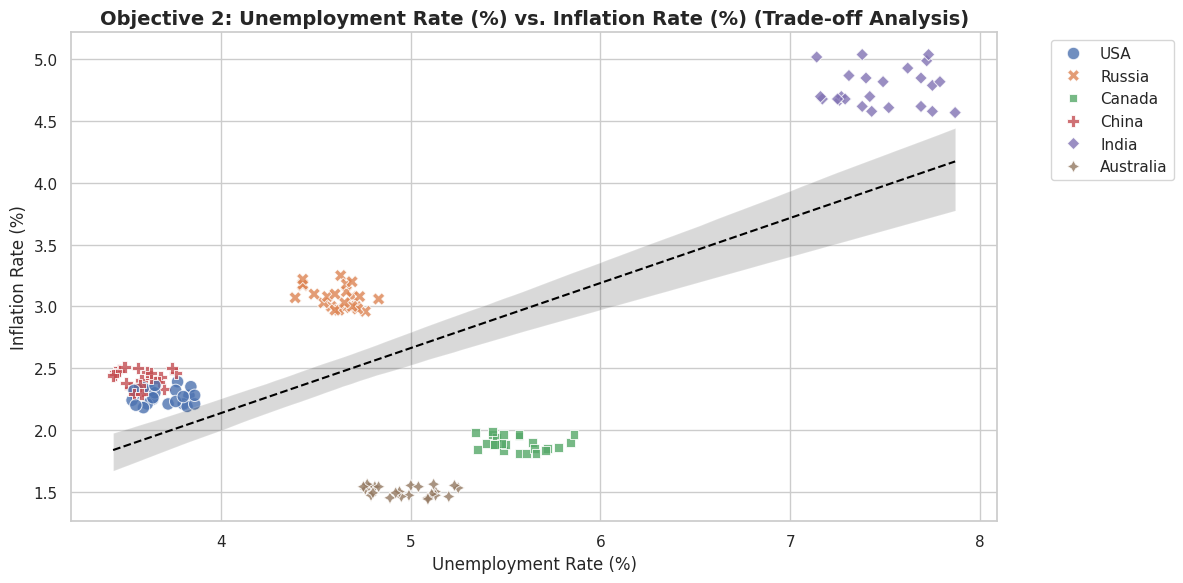

In [6]:
plt.figure(figsize=(12, 6))

# Scatter plot mapping Unemployment vs. Inflation across countries
sns.scatterplot(
    data=df,
    x='Unemployment Rate (%)',
    y='Inflation Rate (%)',
    hue='Country',
    style='Country',
    alpha=0.8,
    s=80
)

# Draw an overall trendline to assess Phillips Curve application
sns.regplot(
    data=df,
    x='Unemployment Rate (%)',
    y='Inflation Rate (%)',
    scatter=False,
    color='black',
    line_kws={'linestyle': '--', 'linewidth': 1.5, 'label': 'Overall Economic Trend'}
)

plt.title('Objective 2: Unemployment Rate (%) vs. Inflation Rate (%) (Trade-off Analysis)', fontsize=14, fontweight='bold')
plt.xlabel('Unemployment Rate (%)', fontsize=12)
plt.ylabel('Inflation Rate (%)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Objective 2: Labor & Price Stability Dynamics (Phillips Curve)

What the plot shows: A scatter plot comparing the Unemployment Rate (%) on the x-axis and the Inflation Rate (%) on the y-axis, mapped alongside an overall dashed regression trendline.
Observations: Traditional Keynesian economic theory (the Phillips Curve) suggests an inverse relationship (a downward-sloping trendline) between inflation and unemployment. The slope of the black trendline indicates whether this theoretical trade-off holds true across your selected countries over the 2000–2023 timespan.

### Visualizing Objective 3: Sustainability & Human Progress Links

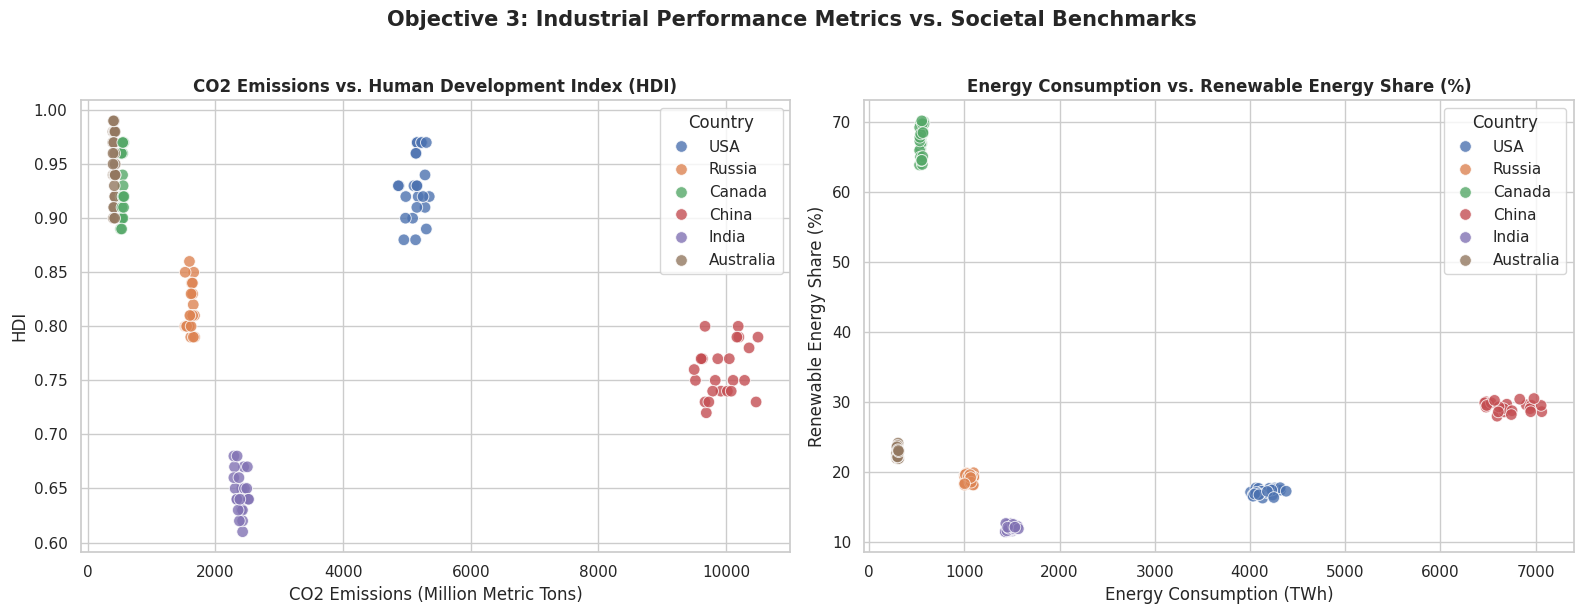

In [7]:
# Subplots looking at Industrial Output vs. HDI & Renewable Energy Share
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: CO2 Emissions vs. Human Development Index
sns.scatterplot(
    ax=axes[0],
    data=df,
    x='CO2 Emissions (Million Metric Tons)',
    y='Human Development Index (HDI)',
    hue='Country',
    s=70,
    alpha=0.8
)
axes[0].set_title('CO2 Emissions vs. Human Development Index (HDI)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('CO2 Emissions (Million Metric Tons)')
axes[0].set_ylabel('HDI')

# Panel B: Energy Consumption vs. Renewable Energy Share
sns.scatterplot(
    ax=axes[1],
    data=df,
    x='Energy Consumption (TWh)',
    y='Renewable Energy Share (%)',
    hue='Country',
    s=70,
    alpha=0.8
)
axes[1].set_title('Energy Consumption vs. Renewable Energy Share (%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Energy Consumption (TWh)')
axes[1].set_ylabel('Renewable Energy Share (%)')

plt.suptitle('Objective 3: Industrial Performance Metrics vs. Societal Benchmarks', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Objective 3: Sustainability & Human Progress Links

Panel A (CO2 Emissions vs. HDI): Examines whether higher human development strictly correlates with industrial emissions. You can observe whether countries are successfully "decoupling" emissions from human progress or if higher HDI continues to yield a larger environmental footprint.
Panel B (Energy Consumption vs. Renewable Energy Share): Highlights whether the largest consumers of energy are transitioning to renewable sources. It contrasts total energy scaling with sustainability targets.